<a href="https://colab.research.google.com/github/ydwi43027-ux/Tugas_Pertemuan_9/blob/main/Estimasi_Titik_dan_Interval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
data = df["total_bill"].sample(
    n=100, random_state=42
).values

print("Jumlah sampel:", len(data))
print(data)

Jumlah sampel: 100
[19.82  8.77 24.55 25.89 13.   17.89 28.44 12.48 14.78 15.38 18.29 10.77
 10.65 14.48 10.07 18.64 18.71 21.58 16.45 41.19 20.69 20.65 14.31  9.55
 20.9  11.69 10.27 25.28 16.49 48.17 38.07  7.74 17.81 20.29 16.97 24.08
 12.03 43.11 13.16 22.67 10.51 14.52 23.95 10.33 10.34  3.07 10.59 18.69
  7.56 13.28 24.27 27.28 31.71 15.98 19.49 13.03  7.25 17.82 17.26 15.69
 29.85 17.31 23.33 16.27 20.23 20.92 15.01  7.25 26.59 24.52 19.77 28.15
 17.29 19.65 15.53 20.45 34.65 25.29 38.01 29.8   9.78 25.71 20.08 11.17
 38.73 16.21 18.35 15.42 24.06 21.7  13.94 29.03  8.52 16.32 17.51 10.29
 40.17 17.47 16.58 17.92]


In [4]:
mean_sample = np.mean(data)

print("Estimasi Titik:", mean_sample)

Estimasi Titik: 19.272100000000002


In [5]:
n = len(data)
std_sample = np.std(data, ddof=1)

z = 1.96

standard_error = std_sample / np.sqrt(n)

lower = mean_sample - z * standard_error
upper = mean_sample + z * standard_error

print("Estimasi Interval Z")
print("Tingkat Kepercayaan: 95%")
print("Batas Bawah:", lower)
print("Batas Atas:", upper)

Estimasi Interval Z
Tingkat Kepercayaan: 95%
Batas Bawah: 17.58308510095219
Batas Atas: 20.961114899047814


In [6]:
jackknife_means = []

for i in range(len(data)):
    sample_jack = np.delete(data, i)
    jackknife_means.append(np.mean(sample_jack))

jackknife_mean = np.mean(jackknife_means)

print("Hasil Jackknife:", jackknife_mean)

Hasil Jackknife: 19.272100000000002


In [7]:
np.random.seed(42)

bootstrap_means = []

for i in range(1000):
    sample_boot = np.random.choice(
        data, size=len(data), replace=True
    )

    bootstrap_means.append(np.mean(sample_boot))

bootstrap_mean = np.mean(bootstrap_means)

print("Jumlah Iterasi: 1000")
print("Hasil Bootstrapping:", bootstrap_mean)

Jumlah Iterasi: 1000
Hasil Bootstrapping: 19.2564301


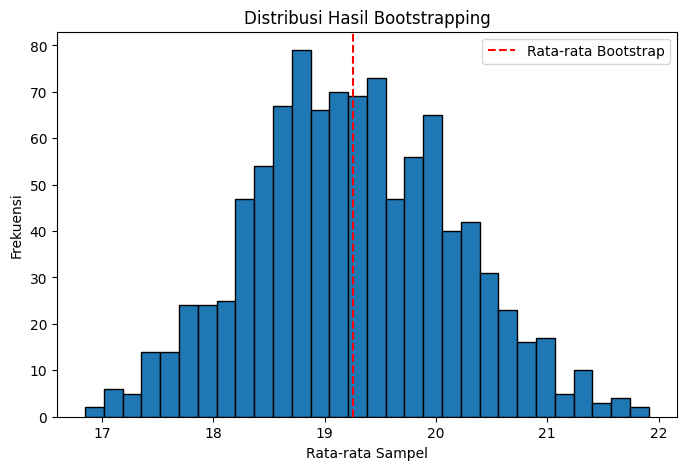

In [8]:
plt.figure(figsize=(8,5))

plt.hist(bootstrap_means, bins=30, edgecolor="black")

plt.axvline(
    bootstrap_mean,
    color="red",
    linestyle="--",
    label="Rata-rata Bootstrap"
)

plt.title("Distribusi Hasil Bootstrapping")
plt.xlabel("Rata-rata Sampel")
plt.ylabel("Frekuensi")
plt.legend()
plt.show()

In [10]:
print("KESIMPULAN")

print("Estimasi Titik:", mean_sample)

print("Estimasi Interval Z:",
      lower, "-", upper)

print("Hasil Jackknife:",
      jackknife_mean)

print("Hasil Bootstrapping:",
      bootstrap_mean)

KESIMPULAN
Estimasi Titik: 19.272100000000002
Estimasi Interval Z: 17.58308510095219 - 20.961114899047814
Hasil Jackknife: 19.272100000000002
Hasil Bootstrapping: 19.2564301
